In [20]:
!pip -q install kagglehub h5py

import kagglehub

dataset_path = kagglehub.dataset_download(
    "johnarevalo/mmimdb"
)

print("Dataset location:", dataset_path)

Using Colab cache for faster access to the 'mmimdb' dataset.
Dataset location: /kaggle/input/mmimdb


In [ ]:
import os

print("Dataset files:")

for file in os.listdir(dataset_path):
    filepath = os.path.join(dataset_path, file)

    if os.path.isfile(filepath):
        size_gb = os.path.getsize(filepath) / (1024**3)
        print(f"{file}: {size_gb:.2f} GB")

Dataset files:
metadata.npy: 0.06 GB
multimodal_imdb.hdf5: 14.57 GB


In [ ]:

import h5py

hdf5_path = os.path.join(
    dataset_path,
    "multimodal_imdb.hdf5"
)

with h5py.File(hdf5_path, "r") as f:
    print("HDF5 contents:")

    for key in f.keys():
        item = f[key]

        print("\nName:", key)

        if isinstance(item, h5py.Dataset):
            print("Shape:", item.shape)
            print("Data type:", item.dtype)

        elif isinstance(item, h5py.Group):
            print("Type: Group")
            print("Subkeys:", list(item.keys())[:20])


HDF5 contents:

Name: features
Shape: (25959, 300)
Data type: float32

Name: genres
Shape: (25959, 23)
Data type: int32

Name: images
Shape: (25959, 3, 256, 160)
Data type: int32

Name: imdb_ids
Shape: (25959,)
Data type: |S7

Name: sequences
Shape: (25959,)
Data type: object

Name: three_grams
Shape: (25959, 9946)
Data type: float32

Name: vgg_features
Shape: (25959, 4096)
Data type: float32

Name: word_grams
Shape: (25959, 13253)
Data type: float32


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:

import os

features_dir = "/content/drive/MyDrive/MMIMDb_Final_Project/features"

print("Features folder exists:", os.path.exists(features_dir))

if os.path.exists(features_dir):
    print("\nSaved files:")
    for file in os.listdir(features_dir):
        path = os.path.join(features_dir, file)
        if os.path.isfile(path):
            print(file, round(os.path.getsize(path) / 1e6, 2), "MB")
else:
    print("Folder not found!")
    print("Available folders:")
    print(os.listdir("/content/drive/MyDrive"))


Features folder exists: True

Saved files:


In [ ]:

import os

drive_root = "/content/drive/MyDrive"

target_files = [
    "resnet50_features.npy",
    "distilbert_features.npy",
    "dataset_splits.npz"
]

print("Searching Google Drive...\n")

found_files = []

for root, dirs, files in os.walk(drive_root):
    for filename in files:
        if filename in target_files:
            full_path = os.path.join(root, filename)
            found_files.append(full_path)
            print("FOUND:", full_path)
            print("Size (MB):",
                  round(os.path.getsize(full_path) / 1e6, 2))

if not found_files:
    print("No matching files found in MyDrive.")


Searching Google Drive...

No matching files found in MyDrive.


In [ ]:

import os

search_dirs = [
    "/content",
    "/kaggle/working"
]

target_files = {
    "resnet50_features.npy",
    "distilbert_features.npy",
    "dataset_splits.npz"
}

found = []

for search_dir in search_dirs:
    if os.path.exists(search_dir):
        for root, dirs, files in os.walk(search_dir):
            # Skip mounted Drive, already searched
            dirs[:] = [
                d for d in dirs
                if not (root == "/content" and d == "drive")
            ]

            for filename in files:
                if filename in target_files:
                    path = os.path.join(root, filename)
                    found.append(path)
                    print("FOUND:", path)

if not found:
    print("No saved feature files found in local storage.")


No saved feature files found in local storage.


In [28]:

import os

project_dir = "/content/drive/MyDrive/MMIMDb_Final_Project"

features_dir = os.path.join(project_dir, "features")
data_dir = os.path.join(project_dir, "data")
models_dir = os.path.join(project_dir, "models")

os.makedirs(features_dir, exist_ok=True)
os.makedirs(data_dir, exist_ok=True)
os.makedirs(models_dir, exist_ok=True)

print("Project folder:", project_dir)
print("Features folder:", features_dir)
print("Data folder:", data_dir)
print("Models folder:", models_dir)


Project folder: /content/drive/MyDrive/MMIMDb_Final_Project
Features folder: /content/drive/MyDrive/MMIMDb_Final_Project/features
Data folder: /content/drive/MyDrive/MMIMDb_Final_Project/data
Models folder: /content/drive/MyDrive/MMIMDb_Final_Project/models


In [29]:

import numpy as np
import os

test_path = os.path.join(features_dir, "save_test.npy")

# Create a small test file
np.save(test_path, np.array([1, 2, 3]))

# Check it was saved correctly
print("File exists:", os.path.exists(test_path))
print("Saved data:", np.load(test_path))

# Remove test file
os.remove(test_path)

print("Google Drive saving test successful!")


File exists: True
Saved data: [1 2 3]
Google Drive saving test successful!


In [21]:

import os
import h5py
import numpy as np
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# Load genre labels
with h5py.File(hdf5_path, "r") as f:
    Y = f["genres"][:]

# Create 70% training and 30% temporary split
split1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

all_idx = np.arange(len(Y))

train_pos, temp_pos = next(
    split1.split(all_idx, Y)
)

train_idx = all_idx[train_pos]
temp_idx = all_idx[temp_pos]

# Split remaining data into validation and testing
split2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_pos, test_pos = next(
    split2.split(temp_idx, Y[temp_idx])
)

val_idx = temp_idx[val_pos]
test_idx = temp_idx[test_pos]

# Create Google Drive directory
data_dir = "/content/drive/MyDrive/MMIMDb_Final_Project/data"
os.makedirs(data_dir, exist_ok=True)

# Save dataset splits
split_path = os.path.join(data_dir, "dataset_splits.npz")

np.savez(
    split_path,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))
print("File saved:", os.path.exists(split_path))
print("Saved location:", split_path)


Training: 18148
Validation: 3908
Testing: 3903
File saved: True
Saved location: /content/drive/MyDrive/MMIMDb_Final_Project/data/dataset_splits.npz


In [30]:
!pip -q install iterative-stratification

In [31]:

import numpy as np
import os

split_path = "/content/drive/MyDrive/MMIMDb_Final_Project/data/dataset_splits.npz"

print("File exists:", os.path.exists(split_path))

if os.path.exists(split_path):
    splits = np.load(split_path)

    print("Training:", len(splits["train_idx"]))
    print("Validation:", len(splits["val_idx"]))
    print("Testing:", len(splits["test_idx"]))


File exists: True
Training: 18148
Validation: 3908
Testing: 3903


In [32]:

import os
import h5py
import kagglehub

# Locate MM-IMDb dataset
dataset_path = kagglehub.dataset_download(
    "johnarevalo/mmimdb"
)

# Define HDF5 file path
hdf5_path = os.path.join(
    dataset_path,
    "multimodal_imdb.hdf5"
)

# Check file availability
print("Dataset path:", dataset_path)
print("HDF5 file exists:", os.path.exists(hdf5_path))

# Check genre labels
with h5py.File(hdf5_path, "r") as f:
    print("Genre shape:", f["genres"].shape)


Using Colab cache for faster access to the 'mmimdb' dataset.
Dataset path: /kaggle/input/mmimdb
HDF5 file exists: True
Genre shape: (25959, 23)


In [33]:

import numpy as np
import os

split_path = "/content/drive/MyDrive/MMIMDb_Final_Project/data/dataset_splits.npz"

print("File exists:", os.path.exists(split_path))

if os.path.exists(split_path):
    splits = np.load(split_path)

    print("Training:", len(splits["train_idx"]))
    print("Validation:", len(splits["val_idx"]))
    print("Testing:", len(splits["test_idx"]))


File exists: True
Training: 18148
Validation: 3908
Testing: 3903


In [34]:

import os
import numpy as np

project_dir = "/content/drive/MyDrive/MMIMDb_Final_Project"
features_dir = os.path.join(project_dir, "features")

image_path = os.path.join(
    features_dir, "resnet50_features.npy"
)

text_path = os.path.join(
    features_dir, "distilbert_features.npy"
)

print("Checking extracted features...\n")

print("Image features exist:", os.path.exists(image_path))
print("Text features exist:", os.path.exists(text_path))

if os.path.exists(image_path):
    image_features = np.load(image_path, mmap_mode="r")
    print("Image feature shape:", image_features.shape)

if os.path.exists(text_path):
    text_features = np.load(text_path, mmap_mode="r")
    print("Text feature shape:", text_features.shape)


Checking extracted features...

Image features exist: False
Text features exist: False


In [24]:

import h5py
import numpy as np
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# Load genre labels
with h5py.File(hdf5_path, "r") as f:
    Y = f["genres"][:]

indices = np.arange(len(Y))

# 70% train, 30% temporary
split1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_pos, temp_pos = next(split1.split(indices, Y))

train_idx = indices[train_pos]
temp_idx = indices[temp_pos]

# Split temporary set equally
split2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_pos, test_pos = next(
    split2.split(temp_idx, Y[temp_idx])
)

val_idx = temp_idx[val_pos]
test_idx = temp_idx[test_pos]

# Verify no overlap
assert not (set(train_idx) & set(val_idx))
assert not (set(train_idx) & set(test_idx))
assert not (set(val_idx) & set(test_idx))

# Save splits
split_path = os.path.join(data_dir, "dataset_splits.npz")

np.savez(
    split_path,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))
print("Saved:", os.path.exists(split_path))


Training: 18148
Validation: 3908
Testing: 3903
Saved: True


In [ ]:

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with h5py.File(hdf5_path, "r") as f:
    genres = f["genres"][:]

print("Genre matrix shape:", genres.shape)
print("First movie labels:", genres[0])
print("Unique values:", np.unique(genres))

genre_counts = genres.sum(axis=0)

genre_df = pd.DataFrame({
    "Genre_Index": range(23),
    "Movie_Count": genre_counts,
    "Percentage": genre_counts / len(genres) * 100
})

display(
    genre_df.sort_values(
        "Movie_Count", ascending=False
    )
)


Genre matrix shape: (25959, 23)
First movie labels: [1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1]
Unique values: [0 1]


,Genre_Index,Movie_Count,Percentage
0,0,13967,53.804076
1,1,8592,33.098347
2,2,5364,20.663354
3,3,5192,20.000770
4,4,3838,14.784853
5,5,3550,13.675411
6,6,2710,10.439539
7,7,2703,10.412574
8,8,2082,8.020340
9,9,2057,7.924034


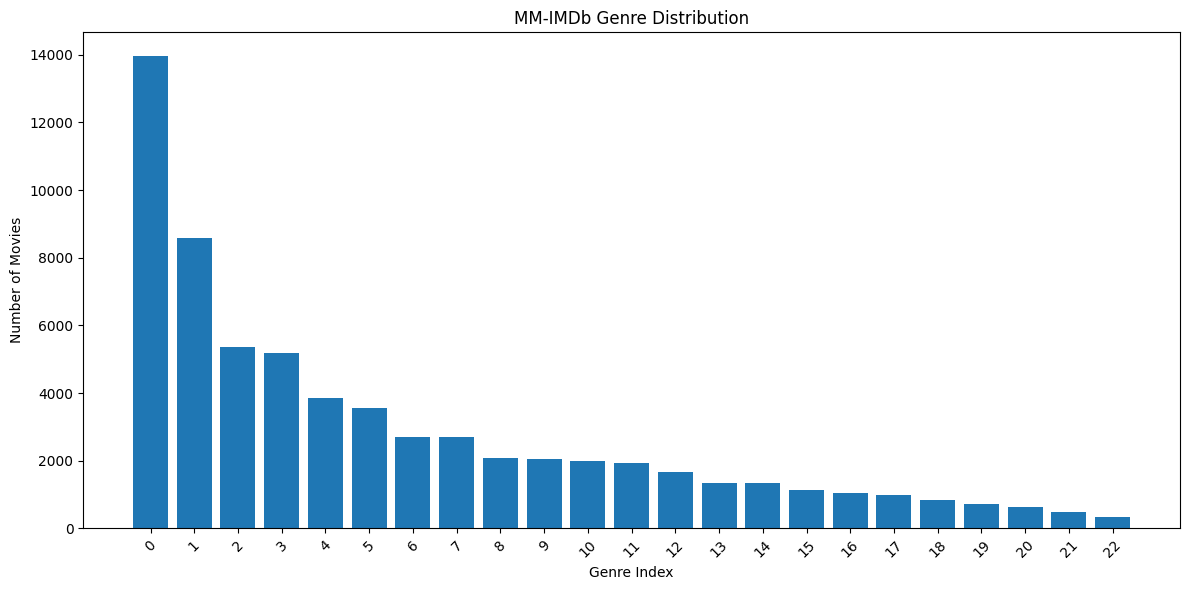

In [ ]:

plt.figure(figsize=(12, 6))

sorted_df = genre_df.sort_values(
    "Movie_Count", ascending=False
)

plt.bar(
    sorted_df["Genre_Index"].astype(str),
    sorted_df["Movie_Count"]
)

plt.xlabel("Genre Index")
plt.ylabel("Number of Movies")
plt.title("MM-IMDb Genre Distribution")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


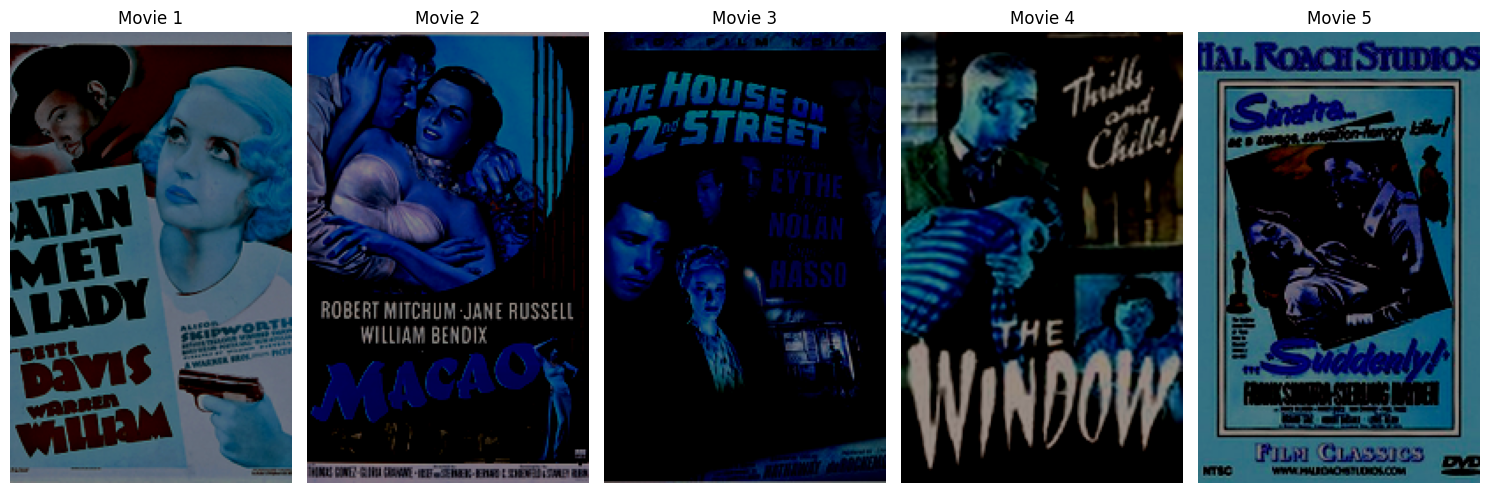

In [ ]:

from PIL import Image
import matplotlib.pyplot as plt

with h5py.File(hdf5_path, "r") as f:
    fig, axes = plt.subplots(1, 5, figsize=(15, 5))

    for i, ax in enumerate(axes):
        image = f["images"][i]

        # Convert channel-first to channel-last
        image = np.transpose(image, (1, 2, 0))

        # Convert to displayable uint8 if needed
        image = np.clip(image, 0, 255).astype(np.uint8)

        ax.imshow(image)
        ax.set_title(f"Movie {i+1}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()


In [ ]:

import os
import numpy as np
import h5py

# Load metadata
metadata_path = os.path.join(
    dataset_path, "metadata.npy"
)

metadata = np.load(
    metadata_path,
    allow_pickle=True
)

print("Metadata shape:", metadata.shape)
print("Metadata type:", type(metadata))

# Extract the metadata object
metadata_obj = (
    metadata.item()
    if metadata.ndim == 0
    else metadata
)

print("\nMetadata object type:")
print(type(metadata_obj))

# Inspect metadata safely
if isinstance(metadata_obj, dict):
    print("\nMetadata keys:")
    print(list(metadata_obj.keys()))

    for key, value in metadata_obj.items():
        print(f"\n{key}:")
        print(repr(value)[:500])
else:
    print("\nMetadata preview:")
    print(repr(metadata_obj)[:2000])

# Inspect text sequences and IMDb IDs
with h5py.File(hdf5_path, "r") as f:

    print("\nFirst text sequence:")
    print(repr(f["sequences"][0])[:1000])

    print("\nFirst IMDb ID:")
    print(f["imdb_ids"][0])


Metadata shape: ()
Metadata type: <class 'numpy.ndarray'>

Metadata object type:
<class 'dict'>

Metadata keys:
['lookup', 'vocab_size', 'word_to_ix', 'ix_to_word']

lookup:
array([[ 8.00781250e-02,  1.04980469e-01,  4.98046875e-02, ...,
         3.66210938e-03,  4.76074219e-02, -6.88476562e-02],
       [ 7.03125000e-02,  8.69140625e-02,  8.78906250e-02, ...,
        -4.76074219e-02,  1.44653320e-02, -6.25000000e-02],
       [ 7.04956055e-03, -7.32421875e-02,  1.71875000e-01, ...,
         1.12304688e-02,  1.64062500e-01,  1.06933594e-01],
       ...,
       [ 7.51953125e-02,  5.54687500e-01, -1.60156250e-01, ...,
        -5.31250000e-01,  2.92968750e-01,  2.0800781

vocab_size:
69980

word_to_ix:
{'complicating': 9988, 'shops': 10358, 'shiela': 21009, 'cosmos': 9989, 'aspercel': 27293, 'induces': 11660, 'indestructable': 32915, 'loft': 7496, 'stomping': 16090, 'disco': 6528, 'bubber': 18931, 'chronically': 32916, 'lingo': 27291, 'parachute': 9919, 'uno': 15405, 'komodos': 42709, 'negl

Total movies: 25959
Average genres per movie: 2.48
Minimum genres: 1
Maximum genres: 10


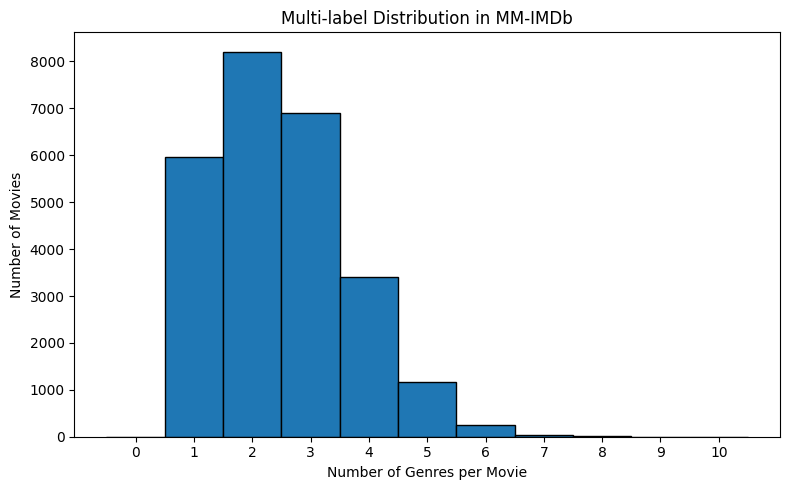

In [ ]:

labels_per_movie = genres.sum(axis=1)

print("Total movies:", len(genres))
print("Average genres per movie:",
      round(labels_per_movie.mean(), 2))

print("Minimum genres:", labels_per_movie.min())
print("Maximum genres:", labels_per_movie.max())

plt.figure(figsize=(8, 5))

plt.hist(
    labels_per_movie,
    bins=np.arange(
        labels_per_movie.max() + 2
    ) - 0.5,
    edgecolor="black"
)

plt.xlabel("Number of Genres per Movie")
plt.ylabel("Number of Movies")
plt.title("Multi-label Distribution in MM-IMDb")
plt.xticks(range(int(labels_per_movie.max()) + 1))
plt.tight_layout()
plt.show()


In [ ]:

# Inspect the metadata structure

metadata_obj = (
    metadata.item()
    if isinstance(metadata, np.ndarray)
    and metadata.ndim == 0
    else metadata
)

print("Metadata type:", type(metadata_obj))

if isinstance(metadata_obj, dict):
    print("\nAvailable metadata keys:")

    for key, value in metadata_obj.items():
        print(
            key,
            "| Type:", type(value).__name__,
            "| Shape:", getattr(value, "shape", "N/A")
        )

        if isinstance(value, (list, tuple, dict, np.ndarray)):
            print("Preview:", repr(value)[:250])
else:
    print("Preview:", repr(metadata_obj)[:1500])


Metadata type: <class 'dict'>

Available metadata keys:
lookup | Type: ndarray | Shape: (41611, 300)
Preview: array([[ 8.00781250e-02,  1.04980469e-01,  4.98046875e-02, ...,
         3.66210938e-03,  4.76074219e-02, -6.88476562e-02],
       [ 7.03125000e-02,  8.69140625e-02,  8.78906250e-02, ...,
        -4.76074219e-02,  1.44653320e-02, -6.25000000e-02],
  
vocab_size | Type: int | Shape: N/A
word_to_ix | Type: dict | Shape: N/A
Preview: {'complicating': 9988, 'shops': 10358, 'shiela': 21009, 'cosmos': 9989, 'aspercel': 27293, 'induces': 11660, 'indestructable': 32915, 'loft': 7496, 'stomping': 16090, 'disco': 6528, 'bubber': 18931, 'chronically': 32916, 'lingo': 27291, 'parachute': 
ix_to_word | Type: dict | Shape: N/A
Preview: {0: '_UNK_', 1: ',', 2: 'the', 3: '.', 4: 'a', 5: 'and', 6: 'to', 7: 'of', 8: 'in', 9: 'is', 10: 'his', 11: "'", 12: 'he', 13: 's', 14: '-', 15: 'with', 16: 'her', 17: 'that', 18: 'for', 19: 'who', 20: 'on', 21: 'as', 22: 'by', 23: 'she', 24: 'they',


In [ ]:
!pip install iterative-stratification

In [ ]:

from iterstrat.ml_stratifiers import (
    MultilabelStratifiedShuffleSplit
)

import numpy as np

# Ensure genre labels are binary
Y = np.asarray(genres)

assert Y.shape == (25959, 23)
assert np.isin(Y, [0, 1]).all()

all_indices = np.arange(len(Y))

# First split: 70% training, 30% temporary
split1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_pos, temp_pos = next(
    split1.split(all_indices, Y)
)

train_idx = all_indices[train_pos]
temp_idx = all_indices[temp_pos]

# Second split: 15% validation, 15% test
split2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_pos, test_pos = next(
    split2.split(temp_idx, Y[temp_idx])
)

val_idx = temp_idx[val_pos]
test_idx = temp_idx[test_pos]

# Check that no records overlap
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

assert (
    len(train_idx) + len(val_idx) + len(test_idx)
    == len(Y)
)

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))


Training samples: 18148
Validation samples: 3908
Testing samples: 3903


In [ ]:

import os

split_dir = os.path.join(
    "/content/drive/MyDrive",
    "MMIMDb_Final_Project",
    "data"
)

os.makedirs(split_dir, exist_ok=True)

np.savez(
    os.path.join(split_dir, "dataset_splits.npz"),
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Dataset splits saved successfully!")


Dataset splits saved successfully!


In [ ]:

import h5py
import numpy as np

with h5py.File(hdf5_path, "r") as f:
    for i in range(3):
        sequence = f["sequences"][i]

        print(f"\nMovie {i+1}")
        print("Type:", type(sequence))
        print("Shape:", np.shape(sequence))
        print("Content preview:")
        print(repr(sequence)[:500])



Movie 1
Type: <class 'numpy.ndarray'>
Shape: (204,)
Content preview:
array([18186,   418,  5100,     1,  1562,    40,     7,    37,   112,
          18,  1805,   544,     1,   923,    18,    94,     5,    10,
         317,    14,   481,    11,    13,   418,  1534,     3,     2,
         254,     9,     8,     4,  3532,   102,     1,     5,  5100,
           1,    19,    28,   136,     2, 39133,     6,  1283,   111,
          15,     4,    32,    14,  3484,  5095,    31,    25,    70,
         752,    20,     2,   428,     1,     9,  5067,    15,   733,
        16

Movie 2
Type: <class 'numpy.ndarray'>
Shape: (87,)
Content preview:
array([    4, 11310,   148,   628,   655,     1,     4,    53,    19,
          28,    80,  5064,     6,   192,  3756, 22755,     5,     4,
        1998,   208,  1796,   487,    20,     2,    32,    14,  6394,
         425,    31,  1797,  1750,     6, 18666,     3,     2,   655,
           9,   520,   661,    22,    25,   172, 11396,    19,   467,
          

In [ ]:

import h5py

# Retrieve token-to-word dictionary
ix_to_word = metadata_obj["ix_to_word"]

def decode_plot(sequence):
    words = []

    for token_id in sequence:
        token_id = int(token_id)

        word = ix_to_word.get(token_id, "<UNK>")

        if isinstance(word, bytes):
            word = word.decode("utf-8", errors="replace")

        words.append(str(word))

    return " ".join(words)

# Decode first three movies
with h5py.File(hdf5_path, "r") as f:
    for i in range(3):
        sequence = f["sequences"][i]
        plot = decode_plot(sequence)

        print(f"\n{'='*50}")
        print(f"MOVIE {i+1}")
        print(f"{'='*50}")
        print(plot[:1500])



MOVIE 1
sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and shane , who has had the forethought to provide himself with a N - dollar commission from an old lady on the train , is welcomed with open arms . when pretty valerie purvis walks in the next day willing to pay over the odds to put a tail on the man who did her wrong , shane ' s way with the ladies looks like paying off yet again . but things start to go wrong when his partner is murdered , and shane himself comes home to find his apartment wrecked by a gentlemanly crook who comes back to apologise - - and to tell him a fascinating fairy - story about the fabled horn of roland that looks like not being so mythical after all . miss purvis wants protection . the police want answers . and all sorts of people want the ' french horn ' . . . but shane is one jump ahead of everyone all the way . well , almost .

MOVIE 2
a

In [ ]:

with h5py.File(hdf5_path, "r") as f:
    for i in range(5):
        plot = decode_plot(f["sequences"][i])

        words = plot.split()
        unknown_count = sum(
            word == "_UNK_" for word in words
        )

        print(f"Movie {i+1}")
        print("Total words:", len(words))
        print("Unknown tokens:", unknown_count)
        print("Preview:", plot[:200])
        print("-" * 50)


Movie 1
Total words: 204
Unknown tokens: 0
Preview: sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and shane , who has had the forethoug
--------------------------------------------------
Movie 2
Total words: 87
Unknown tokens: 0
Preview: a sultry night club singer , a man who has also traveled to many exotic ports and a salesman meet aboard ship on the N - mile trip from hong kong to macao . the singer is quickly hired by an american 
--------------------------------------------------
Movie 3
Total words: 259
Unknown tokens: 0
Preview: prior to the united states entering wwii , the fbi is monitoring known and suspected nazi agents in the country . purely by happenstance , they discover a nazi cell in the us trying to smuggle informa
--------------------------------------------------
Movie 4
Total words: 233
Unknown tokens: 0
Preview: the woodrys live in a new york city t

In [ ]:

print("Metadata keys:")
print(list(metadata_obj.keys()))

print("\nGenre-related metadata:")
for key, value in metadata_obj.items():
    if "genre" in str(key).lower():
        print(key, repr(value)[:1000])

print("\nGenre label matrix:")
print("Shape:", genres.shape)
print("First movie:", genres[0])


Metadata keys:
['lookup', 'vocab_size', 'word_to_ix', 'ix_to_word']

Genre-related metadata:

Genre label matrix:
Shape: (25959, 23)
First movie: [1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1]


In [ ]:

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected.")
    print("Select Runtime > Change runtime type > T4 GPU")


Device: cpu
No GPU detected.
Select Runtime > Change runtime type > T4 GPU


Image shape: (3, 256, 160)
Image dtype: int32
Minimum value: -123
Maximum value: 138
Mean value: 44.1833740234375


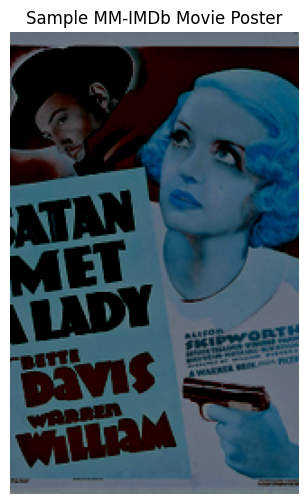

In [ ]:

import h5py
import numpy as np
import matplotlib.pyplot as plt

with h5py.File(hdf5_path, "r") as f:
    image = f["images"][0]

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)
print("Minimum value:", image.min())
print("Maximum value:", image.max())
print("Mean value:", image.mean())

# Convert from (C, H, W) to (H, W, C)
display_image = np.transpose(image, (1, 2, 0))

plt.figure(figsize=(4, 6))

if display_image.max() <= 1 and display_image.min() >= 0:
    plt.imshow(display_image)
else:
    plt.imshow(
        np.clip(display_image, 0, 255).astype(np.uint8)
    )

plt.title("Sample MM-IMDb Movie Poster")
plt.axis("off")
plt.show()


In [ ]:

import torch
import torch.nn as nn

from torchvision.models import (
    resnet50,
    ResNet50_Weights
)

weights = ResNet50_Weights.DEFAULT

image_encoder = resnet50(weights=weights)

# Remove the final classification layer
image_encoder.fc = nn.Identity()

# Freeze pretrained parameters
for parameter in image_encoder.parameters():
    parameter.requires_grad = False

image_encoder = image_encoder.to(device)
image_encoder.eval()

print("ResNet-50 loaded successfully!")
print("Feature dimension: 2048")
print("Device:", device)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 134MB/s]


ResNet-50 loaded successfully!
Feature dimension: 2048
Device: cpu


In [ ]:

import numpy as np
import h5py

with h5py.File(hdf5_path, "r") as f:
    image_array = f["images"][0]

print("Image shape:", image_array.shape)
print("Data type:", image_array.dtype)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())
print("Mean pixel value:", image_array.mean())


Image shape: (3, 256, 160)
Data type: int32
Minimum pixel value: -123
Maximum pixel value: 138
Mean pixel value: 44.1833740234375


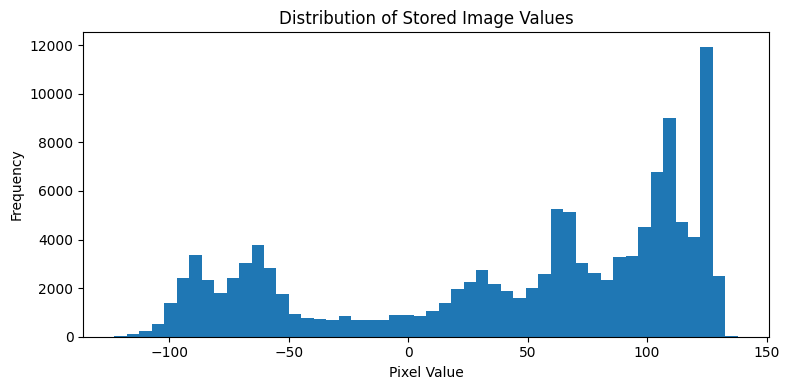

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.hist(
    image_array.flatten(),
    bins=50
)

plt.title("Distribution of Stored Image Values")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


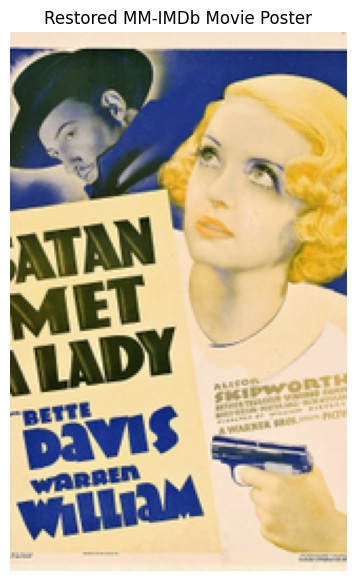

Restored image shape: (256, 160, 3)
Minimum: 0
Maximum: 254


In [ ]:

import numpy as np
import h5py
import matplotlib.pyplot as plt

from PIL import Image

with h5py.File(hdf5_path, "r") as f:
    image_array = f["images"][0]

# Convert from CHW to HWC
image_array = np.transpose(
    image_array.astype(np.float32),
    (1, 2, 0)
)

# Candidate VGG-style mean subtraction
# Assumes stored channel order is BGR
bgr_means = np.array(
    [103.939, 116.779, 123.68],
    dtype=np.float32
)

restored_bgr = image_array + bgr_means

# Convert BGR to RGB
restored_rgb = restored_bgr[:, :, ::-1]

restored_rgb = np.clip(
    restored_rgb, 0, 255
).astype(np.uint8)

plt.figure(figsize=(5, 7))
plt.imshow(restored_rgb)
plt.title("Restored MM-IMDb Movie Poster")
plt.axis("off")
plt.show()

print("Restored image shape:", restored_rgb.shape)
print("Minimum:", restored_rgb.min())
print("Maximum:", restored_rgb.max())


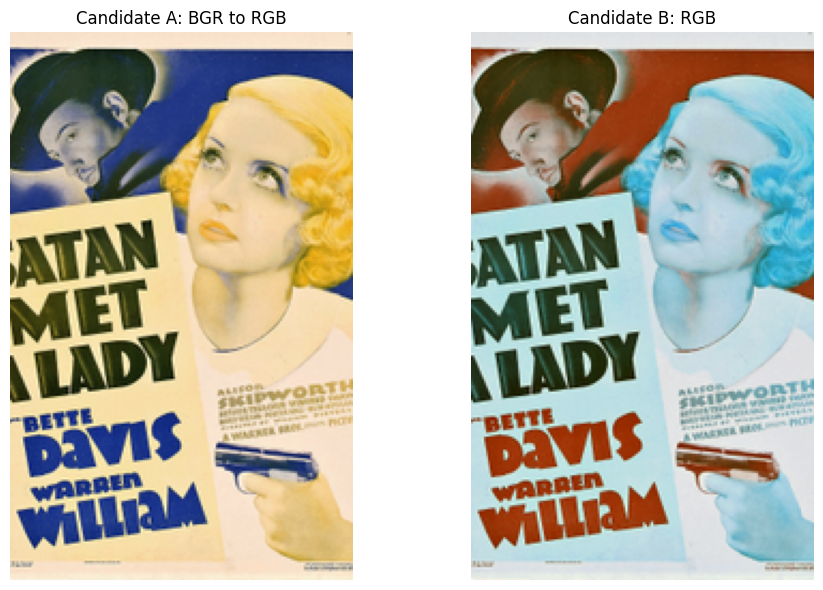

In [ ]:

# Candidate A: BGR with VGG means
candidate_a = restored_rgb

# Candidate B: RGB with channel means
rgb_means = np.array(
    [123.68, 116.779, 103.939],
    dtype=np.float32
)

candidate_b = np.clip(
    image_array + rgb_means,
    0, 255
).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))

axes[0].imshow(candidate_a)
axes[0].set_title("Candidate A: BGR to RGB")
axes[0].axis("off")

axes[1].imshow(candidate_b)
axes[1].set_title("Candidate B: RGB")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [39]:

import os

locations = [
    "/content/drive/MyDrive/MMIMDb_Final_Project",
    "/content/drive/MyDrive/MMIMDb_Final_Project/features",
    "/content",
    "/content/drive/MyDrive"
]

for location in locations:
    print("\nChecking:", location)

    if os.path.exists(location):
        print("Folder exists: YES")
        print("Contents:")
        print(os.listdir(location)[:30])
    else:
        print("Folder exists: NO")



Checking: /content/drive/MyDrive/MMIMDb_Final_Project
Folder exists: YES
Contents:
['features', 'data', 'models']

Checking: /content/drive/MyDrive/MMIMDb_Final_Project/features
Folder exists: YES
Contents:
[]

Checking: /content
Folder exists: YES
Contents:
['.config', 'drive', 'sample_data']

Checking: /content/drive/MyDrive
Folder exists: YES
Contents:
['Colab Notebooks', 'Monthly Expenses.gsheet', 'DOC-20250407-WA0003_', 'Sri Varshan_finalGS (2).docx', 'Multimodel', 'VID-20200112-WA0065 (2).mp4', 'VID-20200112-WA0065 (1).mp4', 'VID-20200112-WA0065.mp4', 'video_20180901_121250.mp4', 'MMIMDb_Final_Project']


In [41]:

import os
import numpy as np
import h5py
import torch
from PIL import Image
from torchvision.models import resnet50, ResNet50_Weights

# Step 1: Set up device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

# Step 2: Load pretrained ResNet-50
weights = ResNet50_Weights.DEFAULT

image_encoder = resnet50(weights=weights)
image_encoder.fc = torch.nn.Identity()
image_encoder = image_encoder.to(device)
image_encoder.eval()

preprocess = weights.transforms()

# Step 3: Locate MMIMDb dataset
if "hdf5_path" not in globals() or not os.path.isfile(hdf5_path):
    import kagglehub
    dataset_path = kagglehub.dataset_download("johnarevalo/mmimdb")
    hdf5_path = os.path.join(dataset_path, "multimodal_imdb.hdf5")

# Step 4: Load first movie poster
with h5py.File(hdf5_path, "r") as f:
    image_array = f["images"][0]

# Step 5: Restore original poster colours
image_array = np.transpose(
    image_array.astype(np.float32),
    (1, 2, 0)
)

bgr_means = np.array(
    [103.939, 116.779, 123.68],
    dtype=np.float32
)

restored_bgr = image_array + bgr_means
restored_rgb = restored_bgr[:, :, ::-1]

restored_rgb = np.clip(
    restored_rgb, 0, 255
).astype(np.uint8)

pil_image = Image.fromarray(restored_rgb)

# Step 6: Prepare image
image_tensor = preprocess(
    pil_image
).unsqueeze(0).to(device)

# Step 7: Extract features
with torch.no_grad():
    image_features = image_encoder(image_tensor)

print("Input shape:", image_tensor.shape)
print("Feature shape:", image_features.shape)
print("Image feature extraction successful!")


Using device: cpu
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:02<00:00, 45.2MB/s]


Input shape: torch.Size([1, 3, 224, 224])
Feature shape: torch.Size([1, 2048])
Image feature extraction successful!


In [42]:

import numpy as np
from PIL import Image

def prepare_movie_poster(image_array):
    # Original shape: (3, 256, 160)
    image_array = np.transpose(
        image_array.astype(np.float32),
        (1, 2, 0)
    )

    # Restore VGG-style BGR channel means
    bgr_means = np.array(
        [103.939, 116.779, 123.68],
        dtype=np.float32
    )

    restored_bgr = image_array + bgr_means

    # Convert BGR to RGB
    restored_rgb = restored_bgr[:, :, ::-1]

    restored_rgb = np.clip(
        restored_rgb, 0, 255
    ).astype(np.uint8)

    # Convert to PIL image
    pil_image = Image.fromarray(restored_rgb)

    # Apply pretrained ResNet-50 transformations
    return preprocess(pil_image)

print("Image preprocessing function created!")


Image preprocessing function created!


In [43]:

import h5py
import torch

with h5py.File(hdf5_path, "r") as f:
    images = [
        prepare_movie_poster(f["images"][i])
        for i in range(5)
    ]

batch = torch.stack(images).to(device)

with torch.no_grad():
    features = image_encoder(batch)

print("Batch shape:", batch.shape)
print("Feature shape:", features.shape)


Batch shape: torch.Size([5, 3, 224, 224])
Feature shape: torch.Size([5, 2048])


In [ ]:

import os
import h5py
import numpy as np
import torch
from tqdm.auto import tqdm

# Google Drive output directory
output_dir = (
    "/content/drive/MyDrive/"
    "MMIMDb_Final_Project/features"
)

os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir, "resnet50_features.npy"
)

batch_size = 32

image_encoder.eval()

with h5py.File(hdf5_path, "r") as f:
    total_images = f["images"].shape[0]

    # Create disk-backed array to avoid excessive RAM use
    all_features = np.lib.format.open_memmap(
        output_path,
        mode="w+",
        dtype=np.float32,
        shape=(total_images, 2048)
    )

    for start in tqdm(
        range(0, total_images, batch_size),
        desc="Extracting ResNet-50 features"
    ):
        end = min(start + batch_size, total_images)

        images = [
            prepare_movie_poster(f["images"][i])
            for i in range(start, end)
        ]

        batch = torch.stack(images).to(device)

        with torch.inference_mode():
            features = image_encoder(batch)

        all_features[start:end] = (
            features.cpu().numpy()
        )

        del batch, features

    all_features.flush()

print("Feature extraction completed!")
print("Saved to:", output_path)
print("Feature shape:", all_features.shape)


Extracting ResNet-50 features:   0%|          | 0/812 [00:00<?, ?it/s]

In [ ]:

import numpy as np
import os

feature_path = (
    "/content/drive/MyDrive/"
    "MMIMDb_Final_Project/features/"
    "resnet50_features.npy"
)

image_features = np.load(
    feature_path,
    mmap_mode="r"
)

print("Feature shape:", image_features.shape)
print("Data type:", image_features.dtype)
print("File size (MB):",
      round(os.path.getsize(feature_path) / 1e6, 2))

print("Contains NaN:",
      np.isnan(image_features).any())

print("Contains infinity:",
      np.isinf(image_features).any())

print("First movie feature preview:")
print(image_features[0][:10])


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/MMIMDb_Final_Project/features/resnet50_features.npy'

In [ ]:
!pip -q install transformers

In [ ]:

import torch

from transformers import (
    AutoTokenizer,
    AutoModel
)

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(
    model_name
)

text_encoder = AutoModel.from_pretrained(
    model_name
)

# Freeze the pretrained model
for param in text_encoder.parameters():
    param.requires_grad = False

text_encoder = text_encoder.to(device)
text_encoder.eval()

print("DistilBERT loaded successfully!")
print("Device:", device)
print("Hidden dimension:", text_encoder.config.dim)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


NameError: name 'device' is not defined

In [ ]:

import h5py

with h5py.File(hdf5_path, "r") as f:
    first_sequence = f["sequences"][0]
    first_plot = decode_plot(first_sequence)

print("Movie plot preview:")
print(first_plot[:400])

# Convert text into DistilBERT tokens
inputs = tokenizer(
    first_plot,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=256
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

with torch.inference_mode():
    outputs = text_encoder(**inputs)

# Attention-mask-aware mean pooling
mask = inputs["attention_mask"].unsqueeze(-1)

text_features = (
    (outputs.last_hidden_state * mask).sum(dim=1)
    / mask.sum(dim=1).clamp(min=1)
)

print("\nTokenised input shape:",
      inputs["input_ids"].shape)

print("Text feature shape:",
      text_features.shape)


NameError: name 'hdf5_path' is not defined

In [ ]:

with h5py.File(hdf5_path, "r") as f:
    plots = [
        decode_plot(f["sequences"][i])
        for i in range(5)
    ]

inputs = tokenizer(
    plots,
    return_tensors="pt",
    padding=True,
    truncation=True,
    max_length=256
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

with torch.inference_mode():
    outputs = text_encoder(**inputs)

mask = inputs["attention_mask"].unsqueeze(-1)

batch_text_features = (
    (outputs.last_hidden_state * mask).sum(dim=1)
    / mask.sum(dim=1).clamp(min=1)
)

print("Number of plots:", len(plots))
print("Text feature shape:",
      batch_text_features.shape)


NameError: name 'hdf5_path' is not defined

In [ ]:

import os
import h5py
import numpy as np
import torch
from tqdm.auto import tqdm

output_dir = (
    "/content/drive/MyDrive/"
    "MMIMDb_Final_Project/features"
)

os.makedirs(output_dir, exist_ok=True)

text_output_path = os.path.join(
    output_dir, "distilbert_features.npy"
)

batch_size = 16
max_length = 256

text_encoder.eval()

with h5py.File(hdf5_path, "r") as f:
    total_movies = f["sequences"].shape[0]

    all_text_features = np.lib.format.open_memmap(
        text_output_path,
        mode="w+",
        dtype=np.float32,
        shape=(total_movies, 768)
    )

    for start in tqdm(
        range(0, total_movies, batch_size),
        desc="Extracting DistilBERT features"
    ):
        end = min(start + batch_size, total_movies)

        # Decode movie plot summaries
        plots = [
            decode_plot(f["sequences"][i])
            for i in range(start, end)
        ]

        # Tokenise plots
        inputs = tokenizer(
            plots,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_length
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        # Extract token embeddings
        with torch.inference_mode():
            outputs = text_encoder(**inputs)

        # Mean pooling excluding padding
        mask = inputs["attention_mask"].unsqueeze(-1)

        features = (
            (outputs.last_hidden_state * mask).sum(dim=1)
            / mask.sum(dim=1).clamp(min=1)
        )

        all_text_features[start:end] = (
            features.cpu().numpy()
        )

        del inputs, outputs, features

    all_text_features.flush()

print("DistilBERT feature extraction completed!")
print("Saved to:", text_output_path)
print("Feature shape:", all_text_features.shape)


NameError: name 'text_encoder' is not defined

In [ ]:

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive connected!")

Mounted at /content/drive
Google Drive connected!


In [ ]:

import numpy as np
import os

text_feature_path = (
    "/content/drive/MyDrive/"
    "MMIMDb_Final_Project/features/"
    "distilbert_features.npy"
)

text_features = np.load(text_feature_path, mmap_mode="r")

print("Feature shape:", text_features.shape)
print("File size (MB):",
      round(os.path.getsize(text_feature_path) / 1e6, 2))

print("First 10 values:", text_features[0][:10])
print("First row all zeros:",
      np.all(text_features[0] == 0))

print("Middle row all zeros:",
      np.all(text_features[len(text_features)//2] == 0))

print("Last row all zeros:",
      np.all(text_features[-1] == 0))

print("Contains NaN:", np.isnan(text_features).any())
print("Contains infinity:", np.isinf(text_features).any())


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/MMIMDb_Final_Project/features/distilbert_features.npy'